# 03. Price curve

A reduced-form price curve gives the weekly load-weighted Swedish price as a function of net import and the German price. This notebook calibrates it on 2015-2025, compares eight variants out of sample, explains the choice of the base model and turns that model into the weekly cost function $C_t(N)$ that the water value model of notebook 04 minimises.

All numbers are computed by `watervalues.price` from `data/processed/weekly_se.csv`. This is the same code that `uv run watervalues price` runs to write the regression table, the variant comparison, the base curve and the report to `outputs/`.

In [1]:
from watervalues import plots
from watervalues.config import PROJECT_ROOT, load_config
from watervalues.data.build import load_weekly
from watervalues.price import build_price

cfg = load_config()
result = build_price(cfg, load_weekly(PROJECT_ROOT / cfg.data.weekly_csv))
report = "\n".join(result.report)
plots.use_style()
print(report[: report.index("Base model")].strip())

Price curve p = alpha + season + gamma p_DE + slope N [EUR/MWh]; N = net import per 168-h stage [GWh] (residual demand - hydro; negative when Sweden exports)
  slope: constant = beta [EUR/MWh per GWh] | proportional = kappa p_DE, kappa [1/GWh]
  cost of covering N in stage t: C_t(N) = a_t N + b_t/2 N^2 [kEUR], a_t = alpha + season_t + gamma p_DE,t
  OLS; HAC (Newey-West, Bartlett) standard errors with 13 lags [weeks]; the weeks on either side of a gap or of excluded years count as neighbours
  seasons: Q1 weeks 1-13, Q2 weeks 14-26, Q3 weeks 27-39, Q4 weeks 40-52 (the first is the reference)

Sample: 568 of 572 weeks complete (2015-2025); weeks left out for missing inputs: 4
  2015-W01: hydro_gwh, load_gwh, nuclear_gwh, wind_gwh, solar_gwh, other_gwh, price_de_eur_mwh
  2015-W50: hydro_gwh, load_gwh, nuclear_gwh, other_gwh, price_se_eur_mwh
  2021-W50: solar_gwh, other_gwh
  2022-W06: other_gwh


## Method

Residual demand is what hydro and trade must cover, and net import $N$ is the part that trade covers:

$$D_w = L_w - G^{nuc}_w - G^{wind}_w - G^{solar}_w - G^{other}_w, \qquad N_w = D_w - P_w \quad [\text{GWh per week}].$$

Since load equals generation plus net import, $N_w$ is approximately Sweden's net import. It is usually negative, because Sweden exports. Energies are per standard 168-hour week: the folded week 52 of a 53-week year is rescaled, while its prices are means over its 336 hours.

The curve explains the weekly Swedish price $p_w$ with the German price $p^{DE}_w$, net import, and an optional seasonal intercept $s_{q(w)}$ for the calendar quarter of the week:

$$p_w = \alpha + s_{q(w)} + \gamma\, p^{DE}_w + b_w N_w + \varepsilon_w, \qquad b_w = \beta \;\; \text{(constant slope)} \quad \text{or} \quad b_w = \kappa\, p^{DE}_w \;\; \text{(proportional slope)}.$$

The constant slope is the simplest reduced form. The proportional slope was added after the diagnostic below showed the slope growing with the price level.

- The coefficients are OLS estimates. The weekly residuals are autocorrelated, so the standard errors are HAC (Newey-West) with a lag of one quarter.
- Out-of-sample accuracy comes from leaving one year out (LOYO): every ISO year is predicted by the variant refitted without that year.
- Weeks with a missing input (listed above) are left out; nothing is imputed.
- Hydro production responds to the price, so $N$ is not exogenous. Controlling for the German price mitigates this only in part (see the limitations).

## Price and net import

Text(0.0, 1.0, 'Swedish price against net import, by period')

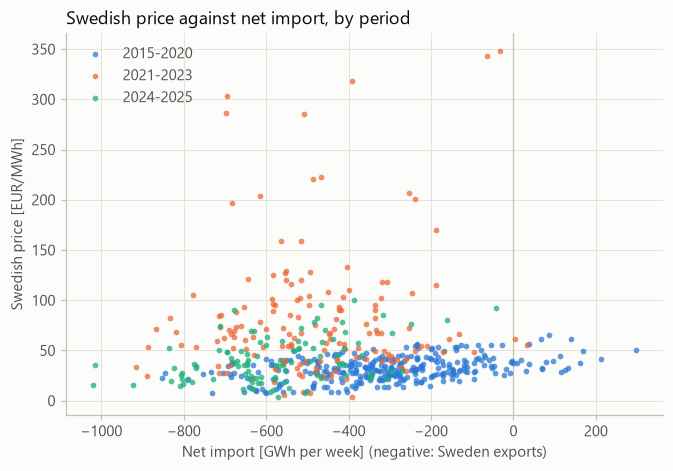

In [2]:
ax = plots.price_vs_net_import(result.table, cfg.price_model.crisis_years)
ax.set_title("Swedish price against net import, by period")

Before 2021 the price rises gently as exports shrink (towards the right). From 2021 the cloud sits higher and spreads much more widely. Most of that spread comes from the German price, which set the price level through the energy crisis. A curve in net import alone could not fit both periods, so the German price has to enter. The next figure asks whether the slope itself depends on it.

## Does the slope grow with the price level?

Fitting the constant-slope curve to each year alone gives one slope per year. If the slope were a fixed property of the system, those yearly slopes would scatter around one value.

Slope of each ISO year fitted alone (constant slope, no seasons): beta [EUR/MWh per GWh], mean German price [EUR/MWh], beta / mean German price [1/GWh]
          beta_eur_mwh_per_gwh  beta_se_eur_mwh_per_gwh  price_de_mean_eur_mwh  beta_per_price_de_per_gwh  nobs
iso_year                                                                                                       
2015                    0.0293                   0.0050                   32.0                   0.000916    50
2016                    0.0213                   0.0019                   29.1                   0.000731    52
2017                    0.0154                   0.0038                   34.2                   0.000449    52
2018                    0.0190                   0.0046                   44.4                   0.000428    52
2019                    0.0190                   0.0051                   37.8                   0.000504    52
2020                    0.0206                   0.0072         

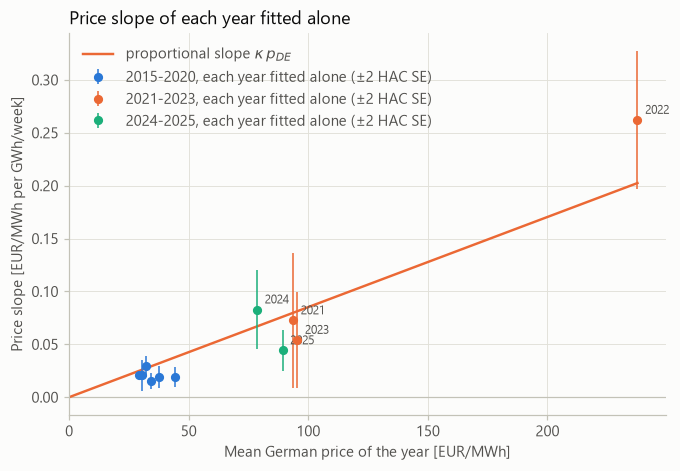

In [3]:
kappa = result.base.kappa_per_gwh  # None if the base model had a constant slope
ax = plots.slope_by_year(result.slopes_by_year, cfg.price_model.crisis_years, kappa_per_gwh=kappa)
ax.set_title("Price slope of each year fitted alone")
print(report[report.index("Slope of each ISO year") : report.index("Weekly curve")].strip())

The yearly slopes do not scatter around one value: they are small in the low-price years before 2021, much larger in 2022, and line up roughly along a ray from the origin. In other words, the price effect of one more GWh of weekly net export is roughly proportional to the German price level. The ratio of slope to German price (last column but one) varies far less between years than the slope itself.

A plausible mechanism: the German price stands for the cost of the continental plants that Swedish exports displace and that imports come from. When that cost is high, each GWh pushed across the interconnectors moves the price more. This motivated the proportional slope $b_w = \kappa\, p^{DE}_w$, drawn as the line.

## Eight variants

The two slope forms are crossed with two further choices: with and without seasonal intercepts, and with and without the energy-crisis years, when the northern and southern Swedish zones decoupled strongly.

The table shows in-sample fit and out-of-sample accuracy. R² compares only variants fitted on the same weeks. The LOYO errors cover the same weeks in all eight variants, so they compare directly. They are also given by period: before, during and after the crisis years. The seasonal bias is the largest mean LOYO error of any quarter.

In [4]:
columns = [
    "n_obs",
    "n_params",
    "slope_t_hac",
    "rsquared",
    "durbin_watson",
    "loyo_rmse_eur_mwh",
    "loyo_rmse_before_eur_mwh",
    "loyo_rmse_crisis_eur_mwh",
    "loyo_rmse_after_eur_mwh",
    "loyo_season_bias_eur_mwh",
]
result.comparison[columns].round(2)

,n_obs,n_params,slope_t_hac,rsquared,durbin_watson,loyo_rmse_eur_mwh,loyo_rmse_before_eur_mwh,loyo_rmse_crisis_eur_mwh,loyo_rmse_after_eur_mwh,loyo_season_bias_eur_mwh
label,,,,,,,,,,
"constant slope, no seasons, all years",568,3,4.82,0.75,0.64,21.50,11.90,34.93,17.23,8.85
"constant slope, no seasons, without 2021-2023",414,3,6.56,0.44,0.67,22.81,9.85,38.69,18.33,8.66
"constant slope, seasonal, all years",568,6,4.83,0.77,0.68,21.37,13.06,34.05,16.42,0.48
"constant slope, seasonal, without 2021-2023",414,6,6.24,0.47,0.69,22.82,10.23,38.59,18.07,7.45
"proportional slope, no seasons, all years",568,3,17.28,0.85,0.93,16.66,8.82,25.68,17.52,4.37
"proportional slope, no seasons, without 2021-2023",414,3,9.90,0.52,0.61,18.83,8.71,30.79,17.53,6.65
"proportional slope, seasonal, all years",568,6,19.03,0.86,0.98,16.73,9.39,25.81,16.72,1.75
"proportional slope, seasonal, without 2021-2023",414,6,9.14,0.55,0.65,18.96,9.16,31.04,16.94,5.17


- The proportional slope beats the constant slope on pooled out-of-sample error in every pairing, most of all in the crisis years. In the years after the crisis the constant slope is sometimes slightly better. Over all years the residuals of the proportional slope are also less autocorrelated, with a Durbin-Watson statistic closer to 2.
- Leaving out the crisis years makes every variant worse in those years, which it then has to extrapolate to. With the proportional slope nothing is gained in the other years; with the constant slope the years before the crisis fit better and the years after it worse.
- Seasonal intercepts hardly change the pooled error over all years, but they remove most of the seasonal bias. Without them, the out-of-sample error keeps a systematic sign in some quarters.

## Choice of the base model

The base model is chosen by a rule that was written down before the final run:

1. the lowest pooled LOYO RMSE of the weekly price over all years;
2. variants within `price_model.selection_tolerance_eur_mwh` of it count as tied, and the smallest LOYO seasonal bias wins;
3. then the fewest parameters.

The variants were explored on this same data before the rule was fixed, so the rule is not a blind pre-registration. Each step has a reason that does not depend on the result:

- The error is pooled over all years because the curve is used for every year of 2015-2025 in the backtest of notebook 05, and at continental price levels that only 2021-2025 reached. Each year is predicted without itself.
- The seasonal bias breaks ties because the water value model moves water between seasons. A cost curve that is too high in one quarter shifts production out of it, which matters more than a fraction of a EUR/MWh of pooled error.
- The number of parameters comes last and only decides between variants that the first two steps cannot separate.

The configuration (`price_model` in `config/base.yaml`) holds the base model. `watervalues price` applies the rule and reports whether the configuration agrees with it, but never changes it.

In [5]:
print(report[report.index("Selection rule") : report.index("Residuals of the base")].strip())

Selection rule: the lowest pooled LOYO RMSE; variants within 0.5 EUR/MWh of it tie, and the smallest LOYO seasonal bias wins, then the fewest parameters
  selected by the rule: proportional slope, seasonal, all years
  configured base model: proportional slope, seasonal, all years (agrees with the rule: yes)


## The base model

In [6]:
print(report[report.index("Base model") : report.index("Variants: fit")].strip())
table = result.table
net_import = table.loc[table["status"] == "used", "net_import_stage_gwh"].mean()
pass_through = float(result.base.de_pass_through(net_import))
print(
    f"\nAt the mean net import ({net_import:.0f} GWh per week) the Swedish price moves "
    f"{pass_through:.2f} EUR/MWh per EUR/MWh of German price."
)

Base model (configured): proportional slope, seasonal, all years
  n = 568 weeks, ISO years 2015-2025
  coefficient      estimate       HAC SE        t  unit
  alpha              7.0234         2.22      3.2  EUR/MWh
  season_Q2         -4.3029         2.51     -1.7  EUR/MWh
  season_Q3         -9.2937         3.69     -2.5  EUR/MWh
  season_Q4         -1.3015         2.57     -0.5  EUR/MWh
  gamma              1.0066       0.0351     28.7  -
  kappa          0.00085213     4.48e-05     19.0  1/GWh
  R2 0.861, adjusted R2 0.860, residual std 15.4 EUR/MWh, Durbin-Watson 0.98, BIC 4752
  slope t-value (kappa) by HAC lags [weeks]: 4: 15.4, 13: 19.0, 26: 20.0, 52: 19.6
  LOYO RMSE 16.7 EUR/MWh; LOYO seasonal bias 1.8 EUR/MWh

At the mean net import (-403 GWh per week) the Swedish price moves 0.66 EUR/MWh per EUR/MWh of German price.


- $\gamma$ is close to one: at balanced trade ($N = 0$) the Swedish price follows the German price almost one for one.
- With exports ($N < 0$) the term $\kappa\, p^{DE} N$ is negative, so the Swedish price trades at a discount to the German price. The discount grows with exports and with the German price. At the mean net import, the Swedish price moves by clearly less than one EUR/MWh per EUR/MWh of German price (printed above).
- The seasonal intercepts are below winter's, most of all in the third quarter, when the snowmelt is still being exported and the northern zones are often cut off from the south. Their standard errors are wide, so they correct the seasonal shape without being precise estimates.
- $\kappa$ stays clearly significant at every HAC lag tried, so the conclusion does not hinge on the choice of lag.

## Fit over time

Text(0.0, 1.0, 'Weekly Swedish price: observed and model')

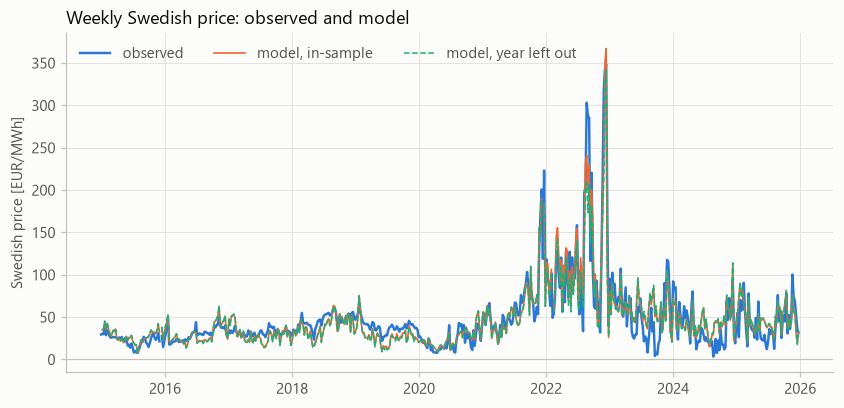

In [7]:
ax = plots.price_fit(result.table)
ax.set_title("Weekly Swedish price: observed and model")

The model follows the price through the crisis, because the German price carries the level. In most years the prediction made with the year left out is close to the in-sample fit, so no single year drives the coefficients. The largest departure is in 2022, the most extreme year (see the residuals by year below).

## Residuals

Residuals of the base model (observed - model) [EUR/MWh]; loyo = out of sample
  by season
        mean   std  loyo_mean  loyo_rmse
season                                  
Q1       0.0  10.9        0.8       10.7
Q2       0.0  12.5        0.8       13.1
Q3       0.0  19.6        1.8       22.3
Q4       0.0  17.1        0.9       18.3
  by ISO year
          mean   std  loyo_mean  loyo_rmse
iso_year                                  
2015      -4.9   4.5       -5.6        7.2
2016       0.3   6.4        0.4        6.8
2017       2.7   8.2        3.2        9.2
2018       7.0   6.6        7.9       10.4
2019      10.9   5.5       12.4       13.6
2020      -2.2   6.5       -2.6        7.1
2021       3.2  12.9        3.7       13.6
2022       0.6  31.2       12.0       35.3
2023      -6.8  21.7       -7.6       23.8
2024      -6.4  15.8       -7.2       17.9
2025      -4.6  14.5       -5.0       15.4
  autocorrelation of the in-sample residuals [weeks]: lag 1: 0.51, lag 4: 0.27, lag 13: 0.

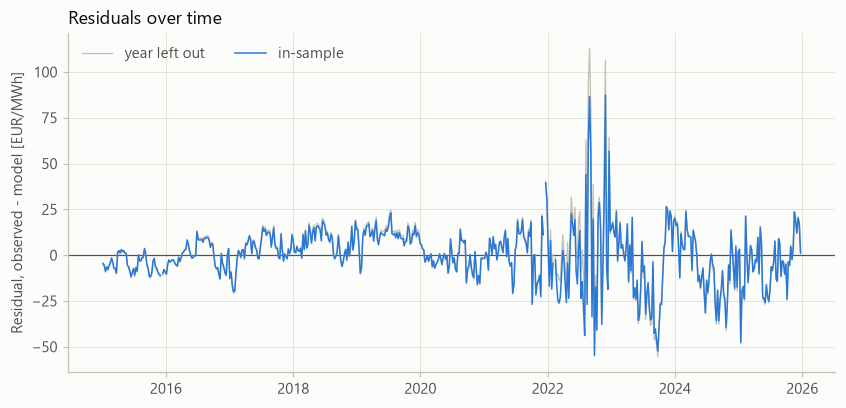

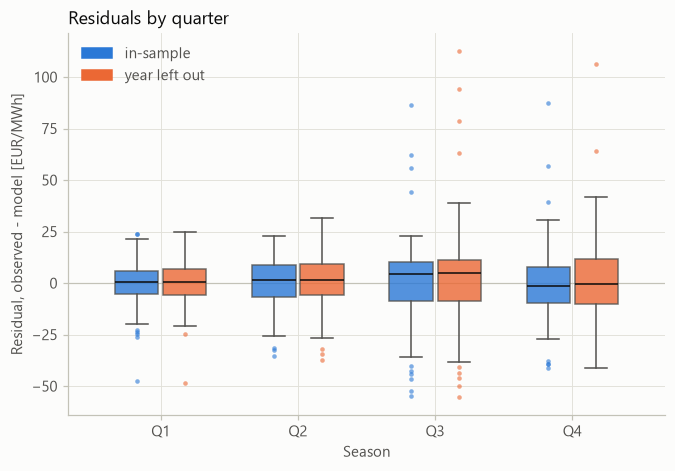

In [8]:
ax = plots.residuals_over_time(result.table)
ax.set_title("Residuals over time")
ax = plots.residuals_by_season(result.table, list(cfg.price_model.seasons))
ax.set_title("Residuals by quarter")
print(
    report[report.index("Residuals of the base") : report.index("Slope of each ISO year")].strip()
)

- The residuals are strongly autocorrelated (lag-1 autocorrelation above, Durbin-Watson in the base model). The model misses slow movements that last for months, such as whole years in which the price stayed above or below the curve. A likely cause is the hydrological balance of the whole Nordic system, Norwegian reservoirs included, which the curve leaves out. This is why the standard errors are HAC.
- They are also much larger from 2021 on: the error in EUR/MWh grows with the price level. The proportional slope reduces this heteroskedasticity but does not remove it.
- The in-sample mean residual of each quarter is zero by construction (seasonal intercepts), and the out-of-sample means are small. The third and fourth quarters are the noisiest.

## The weekly curve and the cost function

For the water value model the curve is evaluated with a 52-week German price profile. That gives one intercept $a_t$ and one slope $b_t = \kappa\, p^{DE}_t$ per stage, and the cost of covering a net import $N$:

$$C_t(N) = a_t N + \tfrac{1}{2}\, b_t N^2 \;\; [\text{kEUR}], \qquad C_t'(N) = p_t(N) = a_t + b_t N, \qquad a_t = \alpha + s_{q(t)} + \gamma\, p^{DE}_t.$$

- $C_t$ is the area under the price curve. With $N$ in GWh and prices in EUR/MWh it comes out in kEUR.
- It is negative for exports, where it is revenue.
- It is convex because $b_t > 0$ in every stage, which the code checks.

The figure shows $b_t$ for the average German price profile of 2015-2025, and for that profile scaled to the continental price levels of the scenarios in notebook 05.

Weekly curve of the base model, a_t [EUR/MWh] and b_t [EUR/MWh per GWh] over 52 stages
  average 2015-2025: German price mean 73.1 EUR/MWh (weeks 45.4 to 114.3); a_t 51.4 to 120.8; b_t 0.0387 to 0.0974
  scaled to 50 EUR/MWh: German price mean 50.0 EUR/MWh (weeks 31.0 to 78.1); a_t 37.0 to 84.4; b_t 0.0265 to 0.0666
  scaled to 80 EUR/MWh: German price mean 80.0 EUR/MWh (weeks 49.7 to 125.0); a_t 55.7 to 131.6; b_t 0.0423 to 0.1065
  scaled to 120 EUR/MWh: German price mean 120.0 EUR/MWh (weeks 74.5 to 187.5); a_t 80.7 to 194.5; b_t 0.0635 to 0.1598
  historical net import per stage: -1020 to 297 GWh (mean -403)
week 30, N = -1000 GWh:   10.6 EUR/MWh, cost    -46025 kEUR
week 30, N =  -400 GWh:   53.1 EUR/MWh, cost    -26916 kEUR
week 30, N =     0 GWh:   81.5 EUR/MWh, cost         0 kEUR
week 30, N =   300 GWh:  102.7 EUR/MWh, cost     27630 kEUR


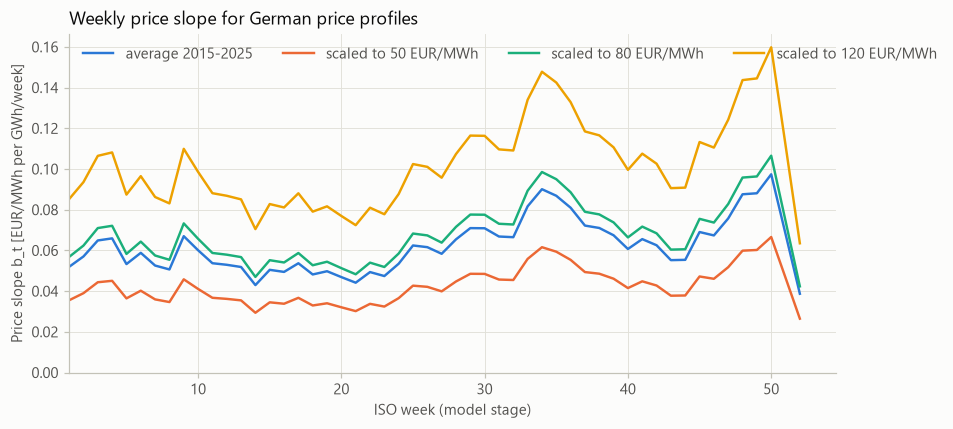

In [9]:
ax = plots.stage_slopes(result.stages)
ax.set_title("Weekly price slope for German price profiles")
print(report[report.index("Weekly curve") :].strip())
stage = next(iter(result.stages.values()))  # the average profile
for net_import in (-1000, -400, 0, 300):
    price, cost = stage.price_eur_mwh(net_import, 30), stage.cost_keur(net_import, 30)
    print(f"week 30, N = {net_import:5d} GWh: {price:6.1f} EUR/MWh, cost {cost:9.0f} kEUR")

The slope follows the German price profile week by week. A higher continental price level makes the whole curve steeper, so each GWh of Swedish net export moves the price more; notebook 05 shows what this does to water values. The average profile itself is jagged and weighted by the 2022 spike, and it drops in the week around Christmas. How to build the base-case profile for the water value model is a decision for notebook 04.

## Limitations

- Hydro production reacts to the price, which biases the OLS slope towards zero, while the Nordic hydrological balance that the curve leaves out can bias it the other way. Controlling for the German price mitigates this endogeneity only in part, and no instrument is used.
- The load-weighted national price hides the split between the northern and southern zones, which was large from 2021.
- The curve is linear in net import, and the water value model evaluates exports beyond the historical range. There the curve gives low or negative prices, and spilling becomes cheaper than exporting.
- The residuals are autocorrelated and larger at high prices. HAC standard errors keep the inference honest, but OLS is not efficient.
- The German price is treated as exogenous. It must be positive in every stage for the proportional slope to be positive, which the code checks.
- Over 2015-2025 the Nordic region gained new interconnectors and much more wind, and flow-based market coupling started in late 2024. One curve averages over all of this structural change.